# 15장 IWAI 2024 종합 예제 (실습)

IWAI 2024 튜토리얼처럼 캡슐 하나에 지금까지의 요소를 모두 담는다. 일반화 좌표, 숨은 상태와 원인 상태 추정, 정밀도 가중 예측 오차, 행동, Gym 형식 환경, 유색 잡음이다. 코드는 「예측 → 예측 오차 → 정밀도 가중 → 경사 하강」 순서를 그대로 따른다.

1. 어디에 있는가 — 추론만
2. 움직이자 — 추론과 행동
3. Hydar 의 하루 — 바뀌는 목표와 유색 잡음
4. 요소를 하나씩 빼 본다 (절제 실험)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 한글 글꼴과 마이너스 기호 설정
from scipy.linalg import cholesky, toeplitz, inv

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (6.4, 3.2), "figure.dpi": 200,
                     "axes.spines.top": False, "axes.spines.right": False})
dt = 0.005

def g(x):  return 25 - 16 / (1 + np.exp(5 - x / 5))                   # 수온 (약층)
def dg(x): e = np.exp(5 - x / 5); return -16 / 5 * e / (1 + e)**2

def derivativeD(p): return np.eye(p + 1, k=1)

def temporalC(p, s2):
    q = np.arange(p + 1); r = np.zeros(1 + 2 * p)
    r[2 * q] = np.cumprod(1 - 2 * q) / (2 * s2)**q
    S = np.empty((0, p + 1))
    for i in range(p + 1):
        S = np.vstack([S, r[q + i]]); r = -r
    return S

def makeNoise(C, s2, t, rng):
    C = np.atleast_2d(C)
    w = cholesky(C, lower=True) @ rng.standard_normal((C.shape[1], t.size))
    if s2 <= 1e-5:
        return w
    P = toeplitz(np.exp(-t**2 / (2 * s2)))
    return w @ (P @ np.diag(1 / np.sqrt(np.diag(P.T @ P))))

print("깊이 25 의 수온", round(g(25.0), 3), "°C,  깊이 15 의 수온", round(g(15.0), 3), "°C")

깊이 25 의 수온 17.0 °C,  깊이 15 의 수온 23.093 °C


## 1. 환경과 캡슐

환경(생성 과정): x′ = u + w, y = g(x) + z. reset/step 으로 감각 ỹ (정확한 일반화 감각)를 돌려준다.

캡슐(생성 모델): Dμ̃x = f̃ + w̃ (f = −μx + μv), ỹ = g̃(μ̃x) + z̃, μ̃v = 사전 + ṽ. 한 걸음은 네 단계다.
1. 예측: f̃, g̃
2. 예측 오차: ε̃x = Dμ̃x − f̃, ε̃y = ỹ − g̃, ε̃v = μ̃v − 사전
3. 정밀도 가중: ξ̃ = Π̃ ε̃
4. 경사 하강: μ̃x, μ̃v, u

절제 실험을 위해 몇 가지 스위치를 둔다: 원인 상태 추정 여부(est_v), 전방 모델의 부호(fwd), 모델이 가정하는 매끄러움(s2_model).

In [2]:
class HydarEnv:
    def __init__(self, t, p, noise="none", s2_x=0.1, s2_y=0.1, s2=1 / 2000, seed=42):
        self.t, self.dt, self.p = t, t[1] - t[0], p
        rng = np.random.default_rng(seed)
        if noise == "smooth":
            self.w, self.z = makeNoise(s2_x, s2, t, rng)[0], makeNoise(s2_y, s2, t, rng)[0]
        else:
            self.w = self.z = np.zeros(t.size)

    def _obs(self, xd):
        full = [g(self.x) + self.z[self.i], dg(self.x) * xd]
        y = np.zeros((self.p + 1, 1)); y[:min(self.p + 1, 2), 0] = full[:min(self.p + 1, 2)]
        return y

    def reset(self, x_init):
        self.i, self.x = 0, x_init
        return self._obs(0.0)

    def step(self, u):
        self.i += 1
        xd = u + self.w[self.i]
        self.x += self.dt * xd
        return self._obs(xd)


class ai_capsule:
    """IWAI 2024 의 캡슐: 일반화 좌표, 숨은·원인 상태 추정, 행동."""

    def __init__(self, x0, p=1, s2_x=0.1, s2_y=0.1, s2_v=0.1, a_x=3.0, a_v=1.0, a_u=8.0,
                 s2_model=1 / 64, est_v=True, fwd=-1.0):
        self.p, self.a_x, self.a_v, self.a_u, self.est_v, self.fwd = p, a_x, a_v, a_u, est_v, fwd
        self.I, self.D = np.eye(p + 1), derivativeD(p)
        self.e0 = self.I[:, :1]
        self.mu_x, self.mu_v, self.u = self.e0 * x0, self.e0 * x0, 0.0
        S = temporalC(p, s2_model)
        self.Pi_x, self.Pi_y, self.Pi_v = (inv(np.kron(S, s)) for s in (s2_x, s2_y, s2_v))

    def ai_step(self, prior, y, act):
        mx, mv = self.mu_x, (self.mu_v if self.est_v else self.e0 * prior)
        g1 = dg(mx[0, 0])
        # 1. 예측
        f_hat = -mx + mv
        y_hat = self.e0 * g(mx[0, 0]) + (1 - self.e0) * g1 * mx
        # 2. 예측 오차
        eps_x, eps_y, eps_v = self.D @ mx - f_hat, y - y_hat, mv - self.e0 * prior
        # 3. 정밀도 가중 예측 오차
        xi_x, xi_y, xi_v = self.Pi_x @ eps_x, self.Pi_y @ eps_y, self.Pi_v @ eps_v
        F = 0.5 * (eps_x.T @ xi_x + eps_y.T @ xi_y + eps_v.T @ xi_v).item()
        # 4. 경사 하강: 숨은 상태, 원인 상태, 행동
        self.mu_x = mx + dt * (self.D @ mx - self.a_x * ((self.D + self.I).T @ xi_x - g1 * xi_y))
        if self.est_v:
            self.mu_v = mv + dt * (self.D @ mv - self.a_v * (-xi_x + xi_v))
        else:
            self.mu_v = mv
        if act:
            self.u += dt * -self.a_u * (self.fwd * np.ones(self.p + 1) @ xi_y[:, 0])
        return self.u, F


def run(prior, T=10.0, x_init=25.0, t_act=3.0, noise="none", **cap_kw):
    t = np.arange(0, T + dt / 2, dt)
    prior = np.broadcast_to(prior, t.shape).astype(float) if np.ndim(prior) == 0 else prior
    p = cap_kw.get("p", 1)
    env = HydarEnv(t, p, noise=noise)
    y = env.reset(x_init)
    cap = ai_capsule(prior[0], **cap_kw)
    rec = {k: np.zeros(t.size) for k in ["x", "y", "mx", "mv", "u", "F"]}
    rec["x"][0], rec["y"][0], rec["mx"][0], rec["mv"][0] = x_init, y[0, 0], prior[0], prior[0]
    u = 0.0
    with np.errstate(all="ignore"):
        for i in range(1, t.size):
            y = env.step(u)
            u, F = cap.ai_step(prior[i], y, t[i] > t_act)
            for k, v in [("x", env.x), ("y", y[0, 0]), ("mx", cap.mu_x[0, 0]), ("mv", cap.mu_v[0, 0]), ("u", u), ("F", F)]:
                rec[k][i] = v
    rec["t"], rec["prior"] = t, prior
    return rec

print("HydarEnv, ai_capsule, run 준비 완료")

HydarEnv, ai_capsule, run 준비 완료


## 2. 어디에 있는가 — 추론만

Hydar 는 깊이 25 에 있고, 사전은 「15 cm 로 간다」다. 행동은 끈다. 원본의 설정(분산 모두 0.1, αx = 3, αv = 1, p = 1, 잡음 없음).

In [3]:
r1 = run(15.0, t_act=99.0)
print(f"실제 깊이 {r1['x'][-1]:.2f}, 실제 수온 {r1['y'][-1]:.3f}")
print(f"10초: 숨은 상태 μx {r1['mx'][-1]:.3f} (예측 수온 {g(r1['mx'][-1]):.3f}),  원인 상태 μv {r1['mv'][-1]:.3f},  F {r1['F'][-1]:.3f}")

실제 깊이 25.00, 실제 수온 17.000
10초: 숨은 상태 μx 24.038 (예측 수온 17.767),  원인 상태 μv 14.872,  F 17.332


## 3. 움직이자 — 추론과 행동

같은 조건에서 3 초부터 행동을 켠다(αu = 8).

In [4]:
r2 = run(15.0, t_act=3.0)
for sec in [2.99, 4, 5, 6, 10]:
    k = int(round(sec / dt))
    print(f"t={sec:5.2f}s  깊이 {r2['x'][k]:6.2f}  수온 {r2['y'][k]:6.2f}  μx {r2['mx'][k]:6.2f}  μv {r2['mv'][k]:6.2f}  u {r2['u'][k]:+6.2f}  F {r2['F'][k]:7.3f}")

t= 2.99s  깊이  25.00  수온  17.00  μx  24.01  μv  14.99  u  +0.00  F  17.178
t= 4.00s  깊이  18.80  수온  21.41  μx  18.90  μv  14.57  u  -3.15  F   3.038
t= 5.00s  깊이  16.81  수온  22.40  μx  16.87  μv  14.69  u  -1.14  F   1.564
t= 6.00s  깊이  16.03  수온  22.72  μx  16.06  μv  14.79  u  -0.52  F   0.758
t=10.00s  깊이  15.18  수온  23.03  μx  15.19  μv  14.96  u  -0.07  F   0.030


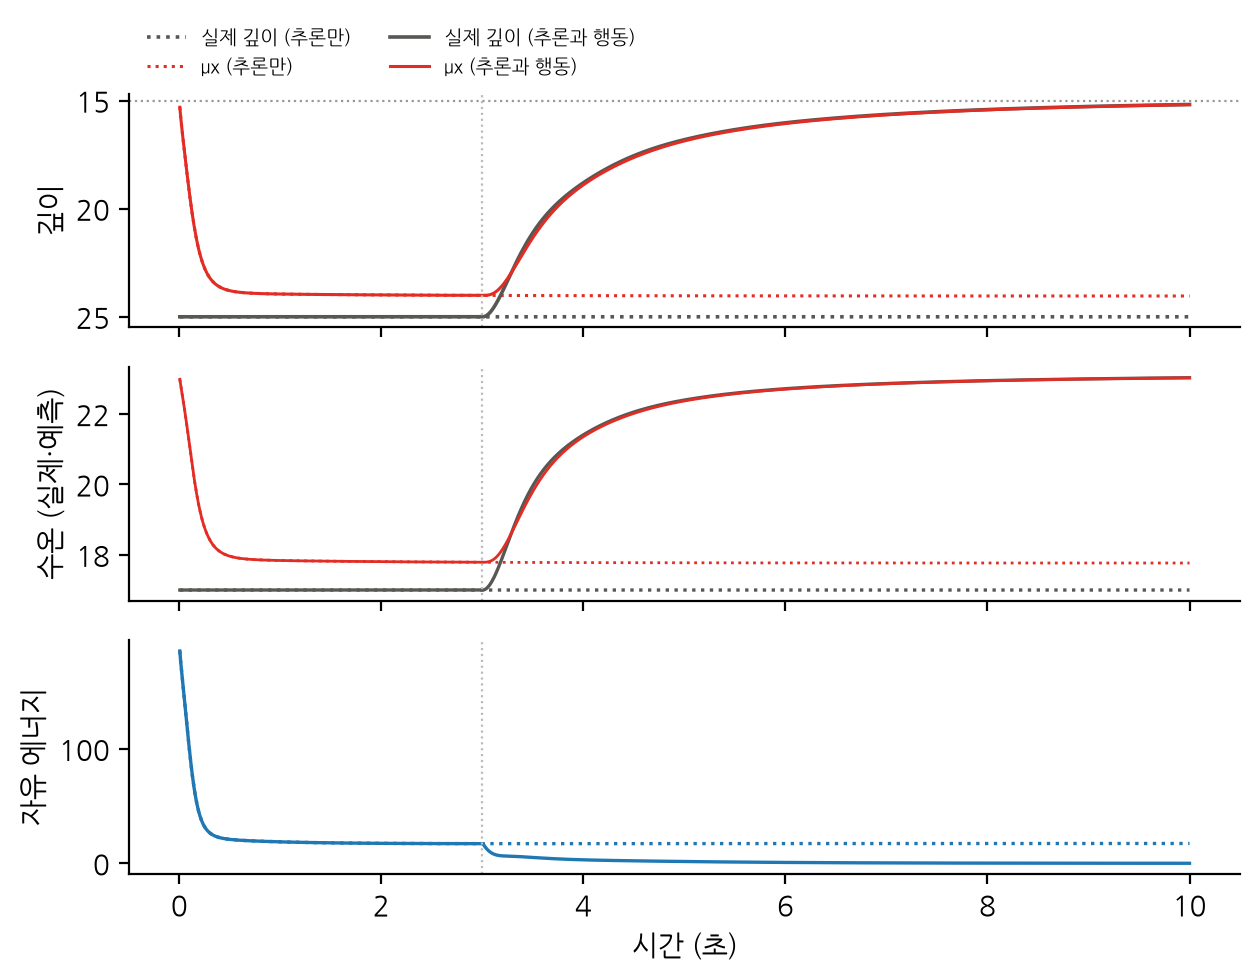

In [5]:
fig, ax = plt.subplots(3, 1, sharex=True, figsize=(6.4, 5.0))
for r_, ls, lab in [(r1, ":", "추론만"), (r2, "-", "추론과 행동")]:
    ax[0].plot(r_["t"][1:], r_["x"][1:], color="#575753", ls=ls, lw=1.3, label=f"실제 깊이 ({lab})")
    ax[0].plot(r_["t"][1:], r_["mx"][1:], color="#E32C24", ls=ls, lw=1.1, label=f"μx ({lab})")
    ax[1].plot(r_["t"][1:], r_["y"][1:], color="#575753", ls=ls, lw=1.2)
    ax[1].plot(r_["t"][1:], g(r_["mx"][1:]), color="#E32C24", ls=ls, lw=1.0)
    ax[2].plot(r_["t"][1:], r_["F"][1:], color="#1f77b4", ls=ls, lw=1.2)
ax[0].axhline(15, color="#999999", lw=0.8, ls=":"); ax[0].invert_yaxis()
ax[0].set_ylabel("깊이"); ax[1].set_ylabel("수온 (실제·예측)"); ax[2].set_ylabel("자유 에너지")
ax[2].set_xlabel("시간 (초)")
ax[0].legend(frameon=False, fontsize=7, ncol=2, loc="lower left", bbox_to_anchor=(0, 1.0))
for a_ in ax:
    a_.axvline(3.0, color="#BBBBBB", lw=0.8, ls=":")
fig.tight_layout(); plt.show()

## 4. Hydar 의 하루

20 초 동안 목표가 바뀐다. 0~7 초는 15 cm, 7~14 초는 30 cm(먹이를 찾아 차가운 물로), 14~20 초는 20 cm. 생성 과정에는 유색 잡음(분산 0.1, 매끄러움 1/2000)이 있고, 캡슐은 그 매끄러움을 알고 있다(s2_model = 1/2000). 행동 학습률은 2 절과 같은 αu = 8 이다. 행동은 0.5 초부터.

In [6]:
T_day = 20.0
t_day = np.arange(0, T_day + dt / 2, dt)
day = np.where(t_day < 7, 15.0, np.where(t_day < 14, 30.0, 20.0))
FULL = dict(p=1, s2_model=1 / 2000, a_u=8.0)

def score(r):
    s = r["t"] > 1
    return np.sqrt(np.mean((r["x"][s] - r["prior"][s])**2))

def seg_arrival(r, t0, t1, target, tol=1.0):
    m = (r["t"] >= t0) & (r["t"] < t1)
    ok = np.abs(r["x"][m] - target) < tol
    idx = np.where(~ok)[0]
    if idx.size == 0:
        return 0.0
    return (r["t"][m][idx[-1] + 1] - t0) if idx[-1] + 1 < ok.size else np.inf

r_day = run(day, T=T_day, t_act=0.5, noise="smooth", **FULL)
print(f"목표 추적 RMSE {score(r_day):.3f}")
for t0, t1, tg in [(0, 7, 15), (7, 14, 30), (14, 20, 20)]:
    a = seg_arrival(r_day, t0, t1, tg)
    m = (r_day["t"] > t1 - 1) & (r_day["t"] < t1)
    print(f"{t0:2d}~{t1:2d}초 목표 {tg} cm: ±1 도착까지 {a:5.2f}s,  구간 마지막 1초 깊이 {r_day['x'][m].mean():6.2f}±{r_day['x'][m].std():.2f}")

목표 추적 RMSE 3.088
 0~ 7초 목표 15 cm: ±1 도착까지   infs,  구간 마지막 1초 깊이  15.86±0.33
 7~14초 목표 30 cm: ±1 도착까지  3.55s,  구간 마지막 1초 깊이  29.67±0.23
14~20초 목표 20 cm: ±1 도착까지  2.80s,  구간 마지막 1초 깊이  20.06±0.21


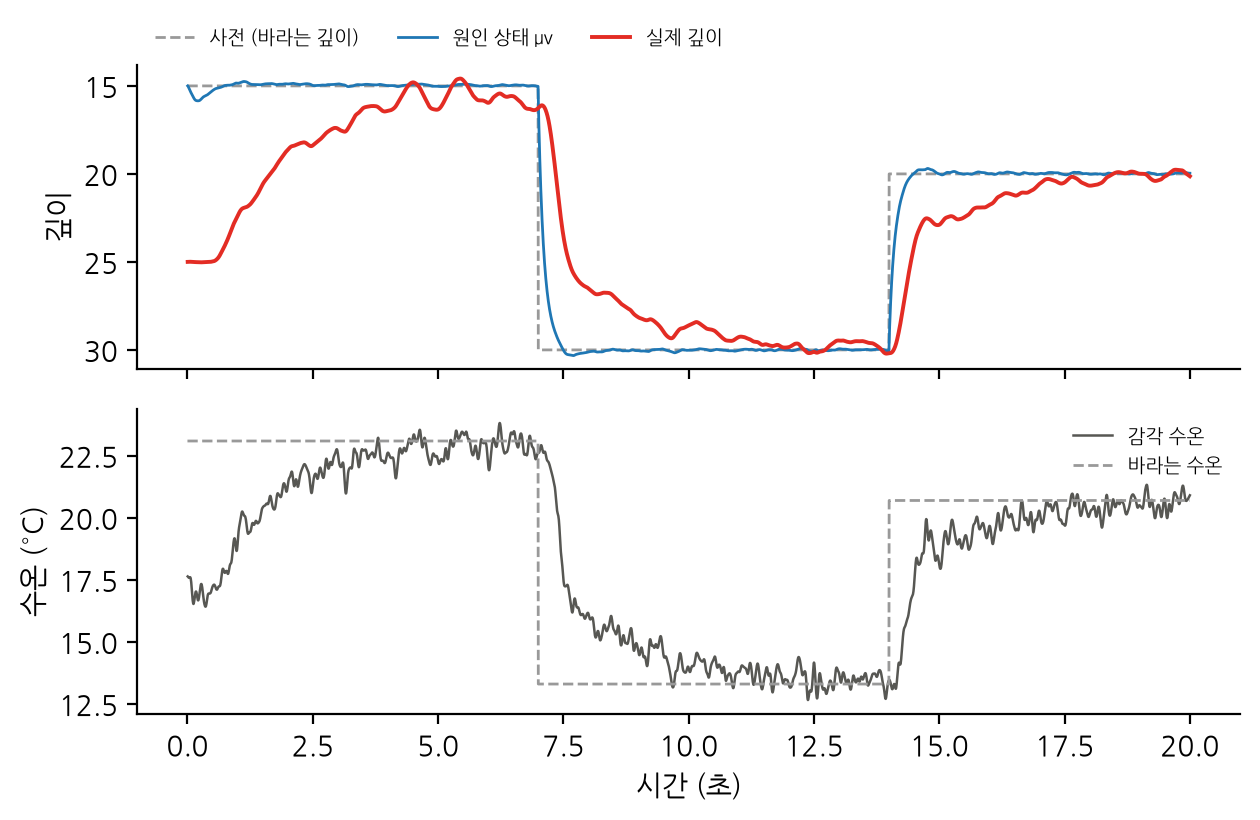

In [7]:
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(6.4, 4.2))
ax[0].plot(t_day, day, color="#999999", lw=1.0, ls="--", label="사전 (바라는 깊이)")
ax[0].plot(t_day[1:], r_day["mv"][1:], color="#1f77b4", lw=1.0, label="원인 상태 μv")
ax[0].plot(t_day[1:], r_day["x"][1:], color="#E32C24", lw=1.4, label="실제 깊이")
ax[0].invert_yaxis(); ax[0].set_ylabel("깊이")
ax[0].legend(frameon=False, fontsize=7, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
ax[1].plot(t_day[1:], r_day["y"][1:], color="#575753", lw=0.9, label="감각 수온")
ax[1].plot(t_day, g(day), color="#999999", lw=1.0, ls="--", label="바라는 수온")
ax[1].set_ylabel("수온 (°C)"); ax[1].set_xlabel("시간 (초)")
ax[1].legend(frameon=False, fontsize=7, loc="upper right")
fig.tight_layout(); plt.show()

## 5. 절제 실험 — 요소를 하나씩 뺀다

Hydar 의 하루를 기준으로, 한 번에 요소 하나만 바꾼다.
- 일반화 좌표 없음 (p = 0)
- 원인 상태 추정 없음 (μv 를 사전에 고정)
- 매끄러움을 잘못 가정 (s2_model = 1, 실제는 1/2000)
- 행동 학습률을 지나치게 키움 (αu = 250)
- 행동 없음 (지각만)
- 전방 모델 부호 반대 (+1)

In [8]:
variants = [
    ("전체 (기준)", dict()),
    ("일반화 좌표 없음 p=0", dict(p=0)),
    ("원인 상태 추정 없음", dict(est_v=False)),
    ("매끄러움 오가정 s²=1", dict(s2_model=1.0)),
    ("행동 학습률 과다 αu=250", dict(a_u=250.0)),
    ("행동 없음", dict(t_act=99.0)),
    ("전방 모델 부호 반대", dict(fwd=+1.0)),
]
print("변형                      추적 RMSE    30cm 구간 도착   마지막 깊이")
for name, kw in variants:
    kw2 = dict(FULL); t_act = kw.pop("t_act", 0.5) if "t_act" in kw else 0.5
    kw2.update(kw)
    r = run(day, T=T_day, t_act=t_act, noise="smooth", **kw2)
    a = seg_arrival(r, 7, 14, 30)
    rm = score(r)
    print(f"{name:20s}   {rm:9.3f}      {('못함' if np.isinf(a) else f'{a:5.2f}s'):>8s}       {r['x'][-1]:9.3g}")

변형                      추적 RMSE    30cm 구간 도착   마지막 깊이


전체 (기준)                    3.088         3.55s            20.1


일반화 좌표 없음 p=0              3.612         3.59s            19.8


원인 상태 추정 없음                2.879         3.55s            20.2


매끄러움 오가정 s²=1              4.402         5.01s            20.4


행동 학습률 과다 αu=250           3.067         6.98s            19.7


행동 없음                      6.973            못함            24.5


전방 모델 부호 반대            11749.425            못함        2.53e+04


## 결론

- 추론만 하면 숨은 상태는 실제 깊이 근처에, 원인 상태는 사전 근처에 자리 잡고, 자유 에너지는 0 이 되지 않는다.
- 행동을 켜면 Hydar 가 바라는 깊이로 가고 자유 에너지가 0 으로 내려간다.
- 바뀌는 목표와 유색 잡음 속에서도 캡슐 하나가 목표를 따라간다.
- 절제 실험은 각 요소가 하는 일을 보여 준다. 행동이 없거나 전방 모델의 부호가 틀리면 목표에 가지 못하고, 행동 학습률이 지나치면 잡음에 휘둘려 흔들린다.